# 03 · Local Places365: multi-mask analysis and adaptive RePaint

**Main goal:** compare mask geometries and evaluate the pilot-guided adaptive RePaint method against fixed and uniform-budget resampling on the five local scene images in `data/places365/`.

This is a Places365 **pilot sample**, not a verified copy of the official Places2 evaluation split. The notebook reuses the project's existing `src/adaptive_repaint.run_comparison` path and does not retrain the model or modify the sampler implementation.

| Setting | Value |
|---|---|
| Images | Up to five files in `data/places365/` |
| Model | Official RePaint Places checkpoint `places256_300000.pt` |
| Masks | Nine families, with 25% and 40% target coverage |
| Samplers | No resampling, fixed RePaint, uniform-budget, adaptive |
| Main comparison | Adaptive vs uniform with equal total denoiser evaluations (pilot included) |
| Metrics | LPIPS, pixel metrics, denoiser-evaluation count (NFE), and wall time |

**Checkpoint setup:** the local setup cell downloads only the Places checkpoint if it is missing; it does not download dataset images, CelebA weights, ImageNet assets, or `data.zip`. A suitable verified Diffusers DDPM checkpoint for the broad Places2/Places365 scene domain was not found, so the notebook does not substitute a bedroom/church model trained for a narrower domain.

## 0 · Setup

In [30]:
# Find the repository root and make `src` importable (the notebook lives in Notebooks/).
# Local setup: open Jupyter from the repo root or set REPAINT_PROJECT_ROOT.
# Set CUDA allocator configuration before importing/allocating CUDA tensors.
import os
import sys
from pathlib import Path

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")

def _find_project_root():
    env = os.environ.get("REPAINT_PROJECT_ROOT")
    candidates = ([Path(env).expanduser()] if env else []) + [Path.cwd(), *Path.cwd().resolve().parents]
    for candidate in candidates:
        if (candidate / "src" / "repaint.py").is_file() and (candidate / "configs" / "faces_places2_study.yaml").is_file():
            return candidate.resolve()
    raise FileNotFoundError("Project root not found (needs src/repaint.py and configs/faces_places2_study.yaml). "
                            "Start Jupyter inside the repository or set REPAINT_PROJECT_ROOT.")

PROJECT_ROOT = _find_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
print("Project root:", PROJECT_ROOT)

Project root: /home/sarthak/programs/budget/Generative_Image_Impainting


In [31]:
# Local Python environment and NVIDIA GPU check. No packages are installed in this cell.
import importlib
import platform
import torch

print("Python      :", platform.python_version())
print("PyTorch     :", torch.__version__, "| CUDA build:", torch.version.cuda, "| CUDA usable:", torch.cuda.is_available())
if torch.cuda.is_available():
    for i in range(torch.cuda.device_count()):
        p = torch.cuda.get_device_properties(i)
        print(f"  GPU {i}: {p.name}, {p.total_memory / 2**30:.1f} GiB")
for name in ("diffusers", "torchvision", "torchmetrics", "lpips", "scipy", "matplotlib", "pandas", "yaml"):
    try:
        module = importlib.import_module(name)
        print(f"{name:12s}:", getattr(module, "__version__", "installed"))
    except Exception as exc:
        print(f"{name:12s}: NOT AVAILABLE ({type(exc).__name__})")
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device      :", DEVICE)
if DEVICE.type == "cuda":
    gpu_gib = torch.cuda.get_device_properties(DEVICE).total_memory / 2**30
    if gpu_gib < 6:
        print(f"LOW-VRAM NOTE: this GPU reports {gpu_gib:.1f} GiB. The Places RePaint model is large; "
              "close GPU-heavy applications and run the smoke test before relying on the full study.")

Python      : 3.10.20
PyTorch     : 2.14.0+cu130 | CUDA build: 13.0 | CUDA usable: True
  GPU 0: NVIDIA GeForce RTX 3050 Laptop GPU, 3.7 GiB
diffusers   : 0.40.0
torchvision : 0.29.0+cu130
torchmetrics: 1.9.0
lpips       : installed
scipy       : 1.15.3
matplotlib  : 3.10.9
pandas      : 2.3.3
yaml        : 6.0.3
Device      : cuda
LOW-VRAM NOTE: this GPU reports 3.7 GiB. The Places RePaint model is large; close GPU-heavy applications and run the smoke test before relying on the full study.


In [32]:
# ---------------------------- run switches ----------------------------------
RUN_SMOKE_FAKE = True          # §4: no checkpoints needed
RUN_SMOKE_REAL = True         # §5: needs the checkpoints, data and LPIPS weights
RUN_FULL_STUDY = True         # §6: long; set deliberately
FULL_BUDGET_PROFILE = "reduced"  # "paper" (T=250, j=10, r=10), "reduced" or "smoke" (configs/faces_places2_study.yaml)
MAX_RUNS_THIS_SESSION = None   # e.g. 40 to split the full study across Kaggle sessions (resumable)
TIME_BUDGET_HOURS = 11.0       # stop starting new runs after this many hours
ALLOW_RANDOM_LPIPS_FOR_SMOKE = False  # software test only: random-backbone LPIPS, marked invalid
# ------------------------------------------------------------------------------

import json
from src.faces_places2_study import load_study_config, budget_settings, check_budget, first_existing

CFG = load_study_config(PROJECT_ROOT)

# ---- Local Places365 pilot override: keep the face dataset out of this run ----
# The folder should contain your five local files: 001.jpg ... 005.jpg.
PLACES_IMAGE_DIR = PROJECT_ROOT / "data" / "places365"
if not PLACES_IMAGE_DIR.is_dir():
    raise FileNotFoundError(f"Expected your local scene images in {PLACES_IMAGE_DIR}")
local_images = sorted(
    p for p in PLACES_IMAGE_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png", ".webp"}
)
if not local_images:
    raise FileNotFoundError(f"No image files found in {PLACES_IMAGE_DIR}")
print(f"Local scene images found: {len(local_images)} in {PLACES_IMAGE_DIR}")

# Reuse the Places guided-diffusion model configuration from the YAML, but replace
# its image path and restrict the study to the local scene images.
places_key = next((k for k in CFG["datasets"] if "places" in k.lower()), None)
if places_key is None:
    raise KeyError("No Places dataset configuration found in configs/faces_places2_study.yaml")
places_cfg = dict(CFG["datasets"][places_key])
places_cfg["data_dirs"] = [str(PLACES_IMAGE_DIR)]
places_cfg["max_images"] = min(5, len(local_images))

# Optional local checkpoint override; avoids assuming a Kaggle-mounted path.
# Example in a terminal before launching Jupyter:
#   export REPAINT_PLACES_CHECKPOINT="$HOME/path/to/places256_300000.pt"
_custom_ckpt = os.environ.get("REPAINT_PLACES_CHECKPOINT")
if _custom_ckpt:
    _custom_ckpt_path = Path(_custom_ckpt).expanduser()
    if not _custom_ckpt_path.is_absolute():
        _custom_ckpt_path = (PROJECT_ROOT / _custom_ckpt_path).resolve()
    places_cfg["checkpoint_candidates"] = [str(_custom_ckpt_path)] + list(places_cfg.get("checkpoint_candidates", []))
    print("Custom Places checkpoint candidate:", _custom_ckpt_path)

CFG["datasets"] = {"places365_local": places_cfg}

# Multi-mask analysis: all supported families, two missing-region sizes.
CFG["masks"]["families"] = [
    "center_square", "random_rectangles", "irregular_brush", "multiple_holes",
    "stripes_horizontal", "stripes_vertical", "large_rectangle",
    "random_blocks", "border_frame",
]
CFG["masks"]["target_ratios"] = [0.25, 0.40]

# Keep this pilot's results separate from any previous face/Places2 runs.
CFG["study"]["results_dir"] = "results/places365_adaptive_5img"
STUDY = CFG["study"]
RESULTS_ROOT = PROJECT_ROOT / STUDY["results_dir"]
print("Study config :", PROJECT_ROOT / "configs" / "faces_places2_study.yaml")
print("Results root :", RESULTS_ROOT)
print("Seeds        : masks", STUDY["mask_base_seed"], "| x_T", STUDY["latent_seed"], "+ image index | noise",
      STUDY["noise_seed"], "+ image index")
for profile in CFG["budgets"]:
    b = budget_settings(CFG, profile); plan = check_budget(b)
    print(f"Budget {profile:8s}: T={b['num_inference_steps']}, j={b['jump_length']}, r={b['jump_n_sample']} | "
          f"fixed {plan.fixed_schedule_nfe} NFE | pilot {plan.pilot_nfe} + base {plan.base_trajectory_nfe} + "
          f"{plan.extra_cycles} cycles x {plan.nfe_per_cycle} = {plan.budgeted_total_nfe} NFE "
          f"(limits {b['min_extra_cycles']}-{b['max_extra_cycles']})")

if RUN_SMOKE_REAL and RUN_FULL_STUDY:
    print("WARNING: both RUN_SMOKE_REAL and RUN_FULL_STUDY are True. If asset checks pass, this notebook runs the real smoke test and then starts the full reduced-budget study in the same execution.")


Local scene images found: 5 in /home/sarthak/programs/budget/Generative_Image_Impainting/data/places365
Study config : /home/sarthak/programs/budget/Generative_Image_Impainting/configs/faces_places2_study.yaml
Results root : /home/sarthak/programs/budget/Generative_Image_Impainting/results/places365_adaptive_5img
Seeds        : masks 2026 | x_T 42 + image index | noise 43 + image index
Budget smoke   : T=50, j=5, r=3 | fixed 140 NFE | pilot 50 + base 50 + 8 cycles x 5 = 140 NFE (limits 0-4)
Budget reduced : T=100, j=10, r=5 | fixed 460 NFE | pilot 100 + base 100 + 26 cycles x 10 = 460 NFE (limits 1-6)
Budget paper   : T=250, j=10, r=10 | fixed 2410 NFE | pilot 250 + base 250 + 191 cycles x 10 = 2410 NFE (limits 3-14)


### Local model setup (only the Places checkpoint, not the dataset)

This setup cell first normalizes the official RePaint code path, then can download **only** the official RePaint Places2 checkpoint (`places256_300000.pt`) from the Google Drive ID referenced by RePaint. It does not download CelebA, Places image data, the ImageNet classifier, or `data.zip`. The configured code path must be the repository root (`external/RePaint`), not `external/RePaint/guided_diffusion`. The checkpoint is large (roughly a few GB), so it requires disk space and a reliable connection.

I searched for a ready-to-use Hugging Face Diffusers DDPM checkpoint trained on the diverse Places2/Places365 scene domain, but could not verify one comparable to `google/ddpm-celebahq-256`. Google's `google/ddpm-bedroom-256` and `google/ddpm-church-256` are real Diffusers DDPM models, but they represent narrower scene domains and are not suitable replacements for a varied Places365 sample. See [bedroom model card](https://huggingface.co/google/ddpm-bedroom-256) and [church model card](https://huggingface.co/google/ddpm-church-256).

For the research question here, keep the Places-specific checkpoint so the adaptive-vs-uniform comparison actually tests a scene-trained model. This preserves the original sampler code and adaptive method.

`DOWNLOAD_PLACES_CHECKPOINT = True` downloads only the Places checkpoint if no candidate file is found. `CLONE_OFFICIAL_REPAINT = True` clones the loader code only when it is missing. `INSTALL_LPIPS = False` is unchanged; install/verify real LPIPS weights separately before full evaluation.

In [33]:
# Local setup: normalize the official RePaint path, then download ONLY the Places checkpoint if missing.
# IMPORTANT: official_code_dirs must point to the REPOSITORY ROOT, whose child is guided_diffusion/unet.py.
# If YAML mistakenly points directly at .../RePaint/guided_diffusion, normalize it to .../RePaint.
CLONE_OFFICIAL_REPAINT = True
DOWNLOAD_PLACES_CHECKPOINT = True
INSTALL_LPIPS = False  # preserved: avoid changing your current PyTorch/CUDA environment

import subprocess
import time

EXTERNAL = PROJECT_ROOT / "external"
REPAINT_REPO = EXTERNAL / "RePaint"
EXPECTED_CKPT = PROJECT_ROOT / "data" / "pretrained" / "places256_300000.pt"
PLACES_GDRIVE_ID = "1QEl-btGbzQz6IwkXiFGd49uQNTUtTHsk"  # Places2 checkpoint referenced by RePaint-based projects


def _repo_root_from_candidate(candidate):
    """Return official RePaint repo root for either repo root or its guided_diffusion subfolder."""
    p = Path(candidate).expanduser()
    if not p.is_absolute():
        p = PROJECT_ROOT / p
    p = p.resolve()
    if (p / "guided_diffusion" / "unet.py").is_file():
        return p
    # Repair the common mistake: config gives <repo>/guided_diffusion, not <repo>.
    if p.name == "guided_diffusion" and (p / "unet.py").is_file():
        parent = p.parent
        if (parent / "guided_diffusion" / "unet.py").is_file():
            return parent
    return None


def _configured_official_dirs():
    value = places_cfg.get("official_code_dirs", [])
    if isinstance(value, (str, Path)):
        return [value]
    return list(value or [])


# First, repair / recognize any existing checkout before attempting a clone.
valid_repo_root = None
for _candidate in _configured_official_dirs() + [REPAINT_REPO]:
    valid_repo_root = _repo_root_from_candidate(_candidate)
    if valid_repo_root is not None:
        break

if valid_repo_root is None and CLONE_OFFICIAL_REPAINT:
    EXTERNAL.mkdir(parents=True, exist_ok=True)
    # Never delete or overwrite an existing folder that may contain user data.
    clone_target = REPAINT_REPO if not REPAINT_REPO.exists() else EXTERNAL / "RePaint_official"
    if clone_target.exists():
        _already_valid = _repo_root_from_candidate(clone_target)
        if _already_valid is not None:
            valid_repo_root = _already_valid
        else:
            alternatives = [EXTERNAL / "RePaint_official_clean", EXTERNAL / "RePaint_official_clean_2"]
            clone_target = next((p for p in alternatives if not p.exists()), None)
            if clone_target is None:
                raise FileNotFoundError(
                    "No valid official RePaint checkout was found and all safe clone destinations already exist. "
                    "Inspect external/RePaint* and choose a clean destination manually; nothing was deleted."
                )
    if valid_repo_root is None:
        print(f"Cloning official RePaint source code into {clone_target} (does not download checkpoints/data)...")
        subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/andreas128/RePaint.git", str(clone_target)],
            check=True,
        )
        valid_repo_root = _repo_root_from_candidate(clone_target)

if valid_repo_root is None:
    paths_checked = [str(p) for p in _configured_official_dirs()] + [str(REPAINT_REPO)]
    raise FileNotFoundError(
        "Official RePaint source not found: expected <repo-root>/guided_diffusion/unet.py. "
        "Set official_code_dirs to the repository root, NOT the guided_diffusion subfolder. "
        f"Paths checked: {paths_checked}"
    )

# The loader validates <configured-dir>/guided_diffusion/unet.py, so save the repo ROOT here.
places_cfg["official_code_dirs"] = [str(valid_repo_root)]
print("Official RePaint repository root:", valid_repo_root)
print("Verified model code:", valid_repo_root / "guided_diffusion" / "unet.py")
print("Config path normalized in memory: official_code_dirs -> repository root")

# Check all configured checkpoint paths. Only download if none is present.
existing_ckpt = first_existing(places_cfg.get("checkpoint_candidates", []), PROJECT_ROOT, want_dir=False)
if existing_ckpt is not None:
    print("Places checkpoint already exists:", existing_ckpt)
elif DOWNLOAD_PLACES_CHECKPOINT:
    EXPECTED_CKPT.parent.mkdir(parents=True, exist_ok=True)
    try:
        import gdown
    except ImportError:
        print("Installing the small 'gdown' download helper (this does not install/upgrade PyTorch)...")
        subprocess.run([sys.executable, "-m", "pip", "install", "gdown"], check=True)
        import gdown
    print("Downloading the official Places checkpoint only. This file is large; do not interrupt the download.")
    downloaded = gdown.download(id=PLACES_GDRIVE_ID, output=str(EXPECTED_CKPT), quiet=False)
    if not downloaded or not EXPECTED_CKPT.is_file():
        raise RuntimeError("Google Drive did not return a checkpoint. Try the official RePaint download instructions manually.")
    # Reject obvious Google Drive quota/error HTML files masquerading as .pt files.
    if EXPECTED_CKPT.stat().st_size < 100_000_000:
        size = EXPECTED_CKPT.stat().st_size
        EXPECTED_CKPT.unlink(missing_ok=True)
        raise RuntimeError(f"Downloaded file was only {size:,} bytes; it is not a complete checkpoint. Google Drive may have blocked the download.")
    print(f"Downloaded checkpoint: {EXPECTED_CKPT} ({EXPECTED_CKPT.stat().st_size / (1024**3):.2f} GiB)")
else:
    print("Checkpoint download disabled. Set DOWNLOAD_PLACES_CHECKPOINT=True to download it.")

if INSTALL_LPIPS:
    subprocess.run([sys.executable, "-m", "pip", "install", "lpips", "--no-deps"], check=True)

# Make the checkpoint candidate visible to the loader without changing any other settings.
if str(EXPECTED_CKPT) not in places_cfg.get("checkpoint_candidates", []):
    places_cfg.setdefault("checkpoint_candidates", []).insert(0, str(EXPECTED_CKPT))

print("Official loader code available:", (valid_repo_root / "guided_diffusion" / "unet.py").is_file())
print("Checkpoint ready:", first_existing(places_cfg.get("checkpoint_candidates", []), PROJECT_ROOT, want_dir=False))


Official RePaint repository root: /home/sarthak/programs/budget/Generative_Image_Impainting/external/RePaint
Verified model code: /home/sarthak/programs/budget/Generative_Image_Impainting/external/RePaint/guided_diffusion/unet.py
Config path normalized in memory: official_code_dirs -> repository root
Places checkpoint already exists: /home/sarthak/programs/budget/Generative_Image_Impainting/data/pretrained/places256_300000.pt
Official loader code available: True
Checkpoint ready: /home/sarthak/programs/budget/Generative_Image_Impainting/data/pretrained/places256_300000.pt


In [34]:
# Asset check, after the optional setup cell has attempted to prepare the model.
from src.study_datasets import resolve_data_dir

def asset_report():
    rows = []
    for name, d in CFG["datasets"].items():
        data_dir = resolve_data_dir(d["data_dirs"], PROJECT_ROOT)
        rows.append({"dataset": name, "asset": "images", "found": data_dir is not None,
                     "path": str(data_dir) if data_dir else " | ".join(map(str, d["data_dirs"]))})
        if d["backend"] == "repaint_guided_diffusion":
            ck = first_existing(d["checkpoint_candidates"], PROJECT_ROOT, want_dir=False)
            code_dir = first_existing(d["official_code_dirs"], PROJECT_ROOT, want_dir=True)
            rows.append({"dataset": name, "asset": "checkpoint", "found": ck is not None,
                         "path": str(ck) if ck else " | ".join(d["checkpoint_candidates"])})
            rows.append({"dataset": name, "asset": "official RePaint code", "found": code_dir is not None,
                         "path": str(code_dir) if code_dir else " | ".join(d["official_code_dirs"])})
        else:
            rows.append({"dataset": name, "asset": "checkpoint", "found": None,
                         "path": f"Hugging Face id {d['model_id']} (loaded/cached by Diffusers)"})
    return rows

import pandas as pd
pd.set_option("display.max_colwidth", 120)
display(pd.DataFrame(asset_report()))

,dataset,asset,found,path
0,places365_local,images,True,/home/sarthak/programs/budget/Generative_Image_Impainting/data/places365
1,places365_local,checkpoint,True,/home/sarthak/programs/budget/Generative_Image_Impainting/data/pretrained/places256_300000.pt
2,places365_local,official RePaint code,True,/home/sarthak/programs/budget/Generative_Image_Impainting/external/RePaint


## 1 · LPIPS (required metric)

Implementation: the `lpips` package (the official PerceptualSimilarity code of Zhang et al., CVPR 2018), v0.1 linear weights, AlexNet backbone, [-1, 1] inputs. Lower means more perceptually similar to the ground truth. It is **not** a measure of semantic correctness or human preference.

* `lpips_full`: LPIPS between the completed (composite) image and the original.
* `lpips_missing_masked`: the spatial LPIPS map (per-layer distance maps upsampled to 256×256 and summed) averaged over the missing pixels only. Nothing is cropped. Receptive fields extend beyond the hole, so this is a hole-weighted perceptual distance, not LPIPS of the hole in isolation.

If initialisation fails, the failure is printed and stored with the results. The full study refuses to run without valid LPIPS.

In [35]:
from src.lpips_metric import load_lpips, lpips_status, LPIPSUnavailableError

# LPIPS stays on DEVICE so evaluation inputs and model weights use the same device.
# The fake smoke test below explicitly uses DEVICE too (the old notebook passed "cpu").
LPIPS_EVAL, LPIPS_ERROR = None, None
try:
    LPIPS_EVAL = load_lpips(net=STUDY.get("lpips_net", "alex"), device=DEVICE)
except LPIPSUnavailableError as exc:
    LPIPS_ERROR = exc
    print("LPIPS COULD NOT BE INITIALISED:\n ", exc)
    print("A full study with require_lpips=True cannot run until genuine pretrained LPIPS weights are available.")
    if ALLOW_RANDOM_LPIPS_FOR_SMOKE:
        try:
            LPIPS_EVAL = load_lpips(net=STUDY.get("lpips_net", "alex"), device=DEVICE, random_backbone=True)
            print("Using a RANDOM-backbone LPIPS for the software smoke test only; its values are invalid.")
        except LPIPSUnavailableError as exc2:
            print("Random-backbone LPIPS also failed:", exc2)
LPIPS_META = lpips_status(LPIPS_EVAL, LPIPS_ERROR)
RESULTS_ROOT.mkdir(parents=True, exist_ok=True)
(RESULTS_ROOT / "lpips_status.json").write_text(json.dumps(LPIPS_META, indent=2) + "\n")
print(json.dumps(LPIPS_META, indent=2))

/home/sarthak/miniconda3/envs/repaint/lib/python3.10/site-packages/torchvision/models/_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
/home/sarthak/miniconda3/envs/repaint/lib/python3.10/site-packages/torchvision/models/_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=AlexNet_Weights.IMAGENET1K_V1`. You can also use `weights=AlexNet_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


{
  "lpips_implementation": "lpips (PerceptualSimilarity)",
  "lpips_package_version": "0.1.4",
  "lpips_net": "alex",
  "lpips_version": "0.1",
  "lpips_input_range": "[-1, 1]",
  "lpips_backbone": "torchvision ImageNet weights",
  "lpips_valid": true,
  "lpips_status": "ok",
  "lpips_error": null
}


## 2 · Mask families and coverage (no model needed)

Target vs achieved missing fraction for every applicable family × ratio, for the image indices used by the study. The gallery shows image index 0. The same masks are used for both datasets.

mean           min           max       
mask_target_ratio    0.25   0.40   0.25   0.40   0.25   0.40
mask_family                                                 
border_frame        0.248  0.402  0.248  0.402  0.248  0.402
center_square       0.250  0.400  0.250  0.400  0.250  0.400
irregular_brush     0.251  0.398  0.246  0.393  0.259  0.402
large_rectangle     0.249  0.400  0.249  0.399  0.250  0.400
multiple_holes      0.244  0.396  0.241  0.390  0.248  0.405
random_blocks       0.250  0.398  0.250  0.398  0.250  0.398
random_rectangles   0.247  0.398  0.240  0.390  0.255  0.407
stripes_horizontal  0.250  0.406  0.250  0.406  0.250  0.406
stripes_vertical    0.250  0.406  0.250  0.406  0.250  0.406

Max |actual - target| = 0.0099 over 90 masks; saved mask_coverage.csv


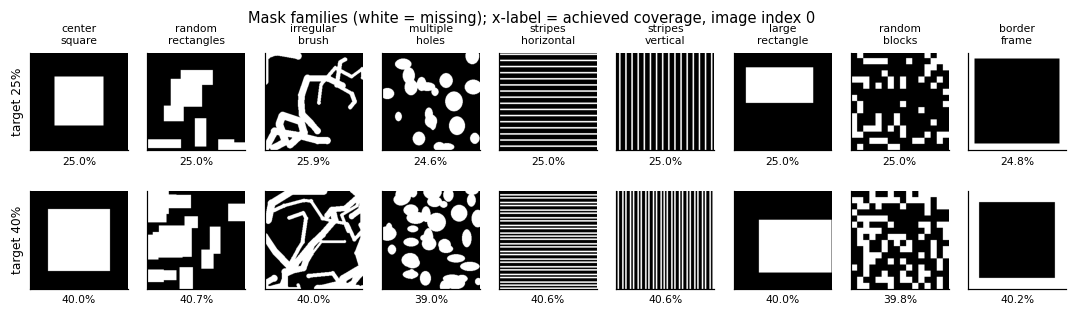

In [36]:
import numpy as np
import matplotlib.pyplot as plt
from src.mask_families import coverage_table, generate_mask, mask_conditions

MASKS = CFG["masks"]
SIZE = int(STUDY["image_size"])
N_INDICES = max(d.get("max_images") or 1 for d in CFG["datasets"].values())
cov = pd.DataFrame(coverage_table(MASKS["families"], MASKS["target_ratios"], SIZE, range(N_INDICES),
                                  int(STUDY["mask_base_seed"]), MASKS.get("not_applicable")))
cov.to_csv(RESULTS_ROOT / "mask_coverage.csv", index=False)
summary = cov.groupby(["mask_family", "mask_target_ratio"])["mask_actual_ratio"].agg(["mean", "min", "max"])
display(summary.unstack("mask_target_ratio").round(3))
print(f"Max |actual - target| = {cov.mask_coverage_error.abs().max():.4f} over {len(cov)} masks; saved mask_coverage.csv")

plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 150, "savefig.bbox": "tight", "font.size": 8,
                     "axes.spines.top": False, "axes.spines.right": False})
FIG_ROOT = RESULTS_ROOT / "figures"; FIG_ROOT.mkdir(parents=True, exist_ok=True)
fams, ratios = MASKS["families"], MASKS["target_ratios"]
fig, axes = plt.subplots(len(ratios), len(fams), figsize=(1.35 * len(fams), 1.5 * len(ratios)))
for c, fam in enumerate(fams):
    for r, ratio in enumerate(ratios):
        ax = axes[r, c]; ax.set_xticks([]); ax.set_yticks([])
        if (fam, float(ratio)) in mask_conditions([fam], [ratio], MASKS.get("not_applicable")):
            spec = generate_mask(fam, ratio, SIZE, 0, int(STUDY["mask_base_seed"]))
            ax.imshow(spec.mask[0, 0], cmap="gray", vmin=0, vmax=1)
            ax.set_xlabel(f"{spec.actual_ratio:.1%}", fontsize=7)
        else:
            ax.text(0.5, 0.5, "n/a", ha="center", va="center"); ax.set_frame_on(False)
        if r == 0: ax.set_title(fam.replace("_", "\n"), fontsize=7)
        if c == 0: ax.set_ylabel(f"target {ratio:.0%}")
fig.suptitle("Mask families (white = missing); x-label = achieved coverage, image index 0")
fig.savefig(FIG_ROOT / "masks_gallery.png"); plt.show()

## 3 · Model compatibility checks

Verified from the official code and configs (details in `Docs/faces_places2_mask_lpips_study.md`):

| Property | Faces: `google/ddpm-celebahq-256` | Places scene images: RePaint `places256_300000.pt` | Shared sampler needs |
|---|---|---|---|
| Architecture | diffusers `UNet2DModel` (≈114 M) | guided-diffusion `UNetModel`, 256 ch, attention 32/16/8, scale-shift norm, resblock up/down (552.8 M measured) | `model(x, t).sample` with 3 channels → adapter for Places2 |
| Resolution | 256 | 256 (`image_size: 256`) | 256 |
| Noise schedule | linear β 1e-4 → 0.02, 1000 steps | `noise_schedule: linear`, `diffusion_steps: 1000` (same β) | ᾱ from the scheduler |
| Prediction | ε | ε (`predict_xstart: false`) | ε |
| Variance | fixed small | **learned range** (`learn_sigma: true`, 6 output channels) | fixed posterior variance; Places2 learned variance discarded |
| Timestep input | integer 0-999 | integer 0-999 (`rescale_timesteps: false`) | `level × stride` |

The cell below re-checks these at run time on the loaded models (output shape and finiteness, ε prediction, schedule match, respacing divisibility) and times one call. Missing assets are reported, not skipped silently.

In [37]:
from src.faces_places2_study import load_dataset_model
from src.guided_diffusion_adapter import check_model_compatibility

MODELS, COMPAT = {}, {}
if DEVICE.type == "cuda":
    torch.cuda.empty_cache()
LOAD_REAL_MODELS = RUN_SMOKE_REAL or RUN_FULL_STUDY
for name, dcfg in CFG["datasets"].items():
    if not LOAD_REAL_MODELS:
        COMPAT[name] = {"status": "not loaded (RUN_SMOKE_REAL and RUN_FULL_STUDY are False)"}
        continue
    try:
        model, scheduler, info = load_dataset_model(dcfg, PROJECT_ROOT, DEVICE)
        report = check_model_compatibility(model, scheduler, SIZE, budget_settings(CFG, FULL_BUDGET_PROFILE)["num_inference_steps"], DEVICE)
        MODELS[name] = (model, scheduler, info)
        COMPAT[name] = {"status": "loaded", **info, **report}
    except torch.cuda.OutOfMemoryError as exc:
        if DEVICE.type == "cuda":
            torch.cuda.empty_cache()
        COMPAT[name] = {"status": f"FAILED: CUDA out of memory while loading/checking model: {exc}. Close other GPU jobs; the checkpoint may exceed available VRAM."}
    except Exception as exc:
        COMPAT[name] = {"status": f"FAILED: {type(exc).__name__}: {exc}"}
(RESULTS_ROOT / "model_compatibility.json").write_text(json.dumps(COMPAT, indent=2, default=str) + "\n")
for name, rep in COMPAT.items():
    print(f"--- {name}")
    for k in ("status", "model_identifier", "parameters_million", "learned_variance_discarded", "prediction_type",
              "beta_schedule", "alphas_cumprod_max_abs_diff_vs_guided_diffusion_linear", "output_shapes",
              "output_finite", "seconds_per_call", "compatible"):
        if k in rep: print(f"  {k}: {rep[k]}")

--- places365_local
  status: loaded
  model_identifier: RePaint official places256_300000.pt
  parameters_million: 552.814086
  learned_variance_discarded: True
  prediction_type: epsilon
  beta_schedule: linear
  alphas_cumprod_max_abs_diff_vs_guided_diffusion_linear: 2.4768675355169023e-07
  output_shapes: [[1, 3, 256, 256], [1, 3, 256, 256]]
  output_finite: True
  seconds_per_call: 0.4397235120013647
  compatible: True


## 4 · Smoke test A: fake denoisers, synthetic images (no checkpoints)

Exercises the whole study pipeline (masks, all four samplers, NFE checks, LPIPS if available, saving, aggregation, figures) on 64×64 synthetic images with a fake denoiser. The images and metrics carry **no information** about real inpainting quality.

In [38]:
import copy
from PIL import Image
from src.faces_places2_study import run_study, write_study_summaries
from src.guided_diffusion_adapter import make_linear_ddpm_scheduler
from types import SimpleNamespace

class FakeDenoiser:
    def __call__(self, sample, timesteps):
        t = timesteps.to(sample.dtype).view(-1, 1, 1, 1) / 1000.0
        return SimpleNamespace(sample=0.5 * torch.tanh(sample) + 0.1 * t * sample.roll(1, dims=-1))
    def parameters(self): return iter(())

SMOKE_FAKE_ROOT = RESULTS_ROOT / "smoke_fake"
if RUN_SMOKE_FAKE:
    fake_cfg = copy.deepcopy(CFG); fake_cfg["study"]["image_size"] = 64
    fake_cfg["masks"]["families"] = ["center_square", "irregular_brush", "stripes_horizontal", "border_frame"]
    fake_cfg["masks"]["target_ratios"] = [0.25, 0.6]
    datasets = {}
    for d, name in enumerate(CFG["datasets"]):
        img_dir = SMOKE_FAKE_ROOT / "_synthetic_inputs" / name; img_dir.mkdir(parents=True, exist_ok=True)
        images = []
        for i in range(2):
            g = np.random.default_rng(100 * d + i)
            yy, xx = np.mgrid[0:64, 0:64] / 63.0
            base = np.stack([xx, yy, (xx + yy) / 2], -1) if d == 0 else np.stack([np.sin(8 * xx), yy, np.cos(5 * yy)], -1) * 0.5 + 0.5
            arr = (np.clip(base + 0.05 * g.standard_normal(base.shape), 0, 1) * 255).astype(np.uint8)
            path = img_dir / f"synthetic_{i}.png"; Image.fromarray(arr).save(path); images.append(path)
        datasets[name] = {"model": FakeDenoiser(), "scheduler": make_linear_ddpm_scheduler(1000),
                          "model_info": {"backend": "fake", "model_identifier": f"FakeDenoiser ({name} stand-in)",
                                         "learned_variance_discarded": False},
                          "config": CFG["datasets"][name], "images": images, "image_root": img_dir}
    # Use the same device as LPIPS_EVAL. The old literal "cpu" caused cuda:0/cpu mismatch.
    manifest = run_study(datasets, fake_cfg, budget_settings(CFG, "smoke"), SMOKE_FAKE_ROOT, DEVICE,
                         LPIPS_EVAL, LPIPS_META, require_lpips=False, overwrite=True, log=lambda *a: None)
    print(f"Smoke A (device={DEVICE}): {manifest['completed_this_call']} runs in {manifest['elapsed_s']:.1f} s; LPIPS status: {LPIPS_META['lpips_status']}")
    print("Summaries:", list(write_study_summaries(SMOKE_FAKE_ROOT)))
else:
    print("Smoke A skipped.")

Smoke A (device=cuda): 16 runs in 3.2 s; LPIPS status: ok
Summaries: ['per_image_results.csv', 'summary_by_condition.csv', 'paired_adaptive_vs_uniform.csv', 'paired_adaptive_vs_fixed.csv', 'mask_difficulty_ranking.csv', 'relative_to_no_resampling.csv']


## 5 · Smoke test B: official Places checkpoint, one local image, tiny budget

Uses the `smoke` budget (T = 50, j = 5, r = 3) on two mask families at 25% target coverage. It checks the real Places scene model and shared sampler end to end; it is far too small for quality conclusions.

The setup cell above attempts to download only `places256_300000.pt` when it is missing and clones the official RePaint code only if needed. If the download is blocked by Google Drive, stop here and follow the [official RePaint repository](https://github.com/andreas128/RePaint) instructions manually.

**Your switches are preserved.** Since `RUN_SMOKE_REAL = True` and `RUN_FULL_STUDY = True`, a successful smoke test is followed by the full reduced-budget 5-image × 9-mask-family × 2-coverage study in the same run. Set only `RUN_FULL_STUDY = False` if you deliberately want smoke-only execution.

In [39]:
from src.study_datasets import dataset_images

def build_datasets(max_images=None, names=None):
    out = {}
    for name, dcfg in CFG["datasets"].items():
        if names and name not in names: continue
        if name not in MODELS:
            print(f"[{name}] SKIPPED: model not loaded ({COMPAT.get(name, {}).get('status')})"); continue
        try:
            cfg_d = dict(dcfg, max_images=max_images if max_images is not None else dcfg.get("max_images"))
            images = dataset_images(cfg_d, PROJECT_ROOT)
        except FileNotFoundError as exc:
            print(f"[{name}] SKIPPED: {exc}"); continue
        model, scheduler, info = MODELS[name]
        out[name] = {"model": model, "scheduler": scheduler, "model_info": info, "config": dcfg, "images": images,
                     "image_root": resolve_data_dir(dcfg["data_dirs"], PROJECT_ROOT)}
        print(f"[{name}] {len(images)} image(s) from {out[name]['image_root']}")
    return out

SMOKE_REAL_ROOT = RESULTS_ROOT / "smoke_real"
if RUN_SMOKE_REAL:
    real = build_datasets(max_images=1)
    if not real:
        details = "; ".join(f"{name}: {meta.get('status', 'unknown')}" for name, meta in COMPAT.items())
        raise RuntimeError(
            "Real smoke test could not start because no real model loaded. "
            "For this local Places365 run, ensure both the official RePaint guided_diffusion code and "
            "places256_300000.pt exist. Put the checkpoint in data/pretrained/ or "
            "external/RePaint/data/pretrained/, or set REPAINT_PLACES_CHECKPOINT to its absolute path "
            "before launching Jupyter. Model status: " + details
        )
    run_study(real, CFG, budget_settings(CFG, "smoke"), SMOKE_REAL_ROOT, DEVICE, LPIPS_EVAL, LPIPS_META,
              families=["center_square", "irregular_brush"], ratios=[0.25], require_lpips=False, overwrite=True)
    print("Summaries:", list(write_study_summaries(SMOKE_REAL_ROOT)))
else:
    print("Smoke B skipped (RUN_SMOKE_REAL = False).")

[places365_local] 1 image(s) from /home/sarthak/programs/budget/Generative_Image_Impainting/data/places365
[places365_local] center_square @ 0.25 (actual 0.250) 001.jpg: 187.2 s
[places365_local] irregular_brush @ 0.25 (actual 0.259) 001.jpg: 187.6 s
Completed 2 run(s), skipped 0 existing
Summaries: ['per_image_results.csv', 'summary_by_condition.csv', 'paired_adaptive_vs_uniform.csv', 'paired_adaptive_vs_fixed.csv', 'mask_difficulty_ranking.csv', 'relative_to_no_resampling.csv']


## 6 · Full multi-mask/adaptive study (explicit opt-in)

The configuration is overridden in §0 to use up to 5 local images, 9 mask families and 2 target coverages (25% and 40%): up to 90 image-mask conditions. It runs `no_resampling`, fixed RePaint, budget-matched uniform and adaptive methods. Uniform and adaptive have equal total denoiser-call budgets; the adaptive pilot is charged to that budget.

**Run only after the real smoke test succeeds.** This notebook keeps your current `RUN_SMOKE_REAL = True`, `RUN_FULL_STUDY = True`, and `FULL_BUDGET_PROFILE = "reduced"` settings, so the full study will follow Smoke B after assets pass. The model checkpoint and valid LPIPS weights must be available. Do not switch to the `paper` budget for this five-image pilot. On a 4 GB-class GPU, close other GPU-heavy programs; if model loading/inference reports CUDA out-of-memory, stop the run rather than interpreting incomplete output.

The five-image result is exploratory. Use paired adaptive-vs-uniform comparisons, per-mask results and NFE/wall-time to identify patterns; it is not enough to claim general improvement or statistical significance.


In [40]:
from src.faces_places2_study import estimate_study_cost, executed_nfe_per_run

FULL_ROOT = RESULTS_ROOT / f"full_{FULL_BUDGET_PROFILE}"
if RUN_FULL_STUDY:
    if STUDY.get("require_lpips", True) and not LPIPS_META.get("lpips_valid", False):
        raise RuntimeError(
            "RUN_FULL_STUDY=True but valid pretrained LPIPS is unavailable. Install/check lpips, scipy and "
            "torchvision in this repaint environment, then rerun cells §0–§6. Do not use random-backbone "
            "LPIPS values for research results."
        )
    budget = budget_settings(CFG, FULL_BUDGET_PROFILE)
    full = build_datasets()
    if not full:
        details = "; ".join(f"{name}: {meta.get('status', 'unknown')}" for name, meta in COMPAT.items())
        raise RuntimeError("RUN_FULL_STUDY=True but no model/dataset could be prepared. Check checkpoint, "
                           "official RePaint code, and data/places365. Model status: " + details)
    n_cond = len(mask_conditions(MASKS["families"], MASKS["target_ratios"], MASKS.get("not_applicable")))
    spc = {n: COMPAT[n].get("seconds_per_call") for n in full}
    display(pd.DataFrame(estimate_study_cost({n: len(v["images"]) for n, v in full.items()}, n_cond, budget,
                                             STUDY["methods"], spc)))
    run_study(full, CFG, budget, FULL_ROOT, DEVICE, LPIPS_EVAL, LPIPS_META, require_lpips=STUDY.get("require_lpips", True),
              max_runs=MAX_RUNS_THIS_SESSION, time_budget_hours=TIME_BUDGET_HOURS)
    print("Summaries:", list(write_study_summaries(FULL_ROOT)))
else:
    print("Full study not run (RUN_FULL_STUDY = False).")

[places365_local] 5 image(s) from /home/sarthak/programs/budget/Generative_Image_Impainting/data/places365


,dataset,images,mask_conditions,runs,executed_nfe_per_run,total_nfe,seconds_per_call,estimated_hours
0,places365_local,5,18,90,1380,124200,0.439724,15.170461


[places365_local] center_square @ 0.25 (actual 0.250) 001.jpg: 616.1 s
[places365_local] center_square @ 0.25 (actual 0.250) 002.jpg: 616.1 s
[places365_local] center_square @ 0.25 (actual 0.250) 003.jpg: 616.4 s
[places365_local] center_square @ 0.25 (actual 0.250) 004.jpg: 616.3 s
[places365_local] center_square @ 0.25 (actual 0.250) 005.jpg: 617.9 s
[places365_local] center_square @ 0.40 (actual 0.400) 001.jpg: 619.1 s
[places365_local] center_square @ 0.40 (actual 0.400) 002.jpg: 619.1 s
[places365_local] center_square @ 0.40 (actual 0.400) 003.jpg: 618.9 s
[places365_local] center_square @ 0.40 (actual 0.400) 004.jpg: 618.4 s
[places365_local] center_square @ 0.40 (actual 0.400) 005.jpg: 618.5 s
[places365_local] random_rectangles @ 0.25 (actual 0.250) 001.jpg: 618.3 s
[places365_local] random_rectangles @ 0.25 (actual 0.240) 002.jpg: 618.2 s
[places365_local] random_rectangles @ 0.25 (actual 0.242) 003.jpg: 618.2 s
[places365_local] random_rectangles @ 0.25 (actual 0.250) 004.jpg

## 7 · Analysis (from saved CSV files only)

Uses the most complete results available: full study, then smoke B, then smoke A. Figures go to `<results>/figures/`. Raw metric values are compared **within** a dataset only. Across datasets the notebook compares within-dataset quantities: mask-difficulty ranks, change relative to `no_resampling`, and paired adaptive − uniform differences.

In [41]:
from src.faces_places2_study import collect_results, write_study_summaries

choices = [("full", FULL_ROOT), ("smoke_real", SMOKE_REAL_ROOT), ("smoke_fake", SMOKE_FAKE_ROOT)]
KIND, ROOT = next(((k, r) for k, r in choices if r.exists() and any(r.rglob("study_rows.csv"))), (None, None))
if ROOT is None:
    raise FileNotFoundError("No results yet; run §4, §5 or §6.")
write_study_summaries(ROOT)
DF = pd.read_csv(ROOT / "per_image_results.csv")
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)
LPIPS_OK = DF["lpips_full"].notna().any() and bool(DF["lpips_valid"].fillna(False).astype(bool).all())
PRIMARY = "lpips_full" if DF["lpips_full"].notna().any() else "missing_mae"
print(f"Results: {KIND} ({ROOT}) | {len(DF)} rows | datasets {sorted(DF.dataset.unique())} | "
      f"LPIPS status {sorted(DF.lpips_status.astype(str).unique())}")
if KIND == "smoke_fake":
    print("NOTE: fake-denoiser results. The figures only demonstrate the pipeline; they say nothing about inpainting quality.")
if not LPIPS_OK:
    print("NOTE: LPIPS values are missing or come from a random test backbone; LPIPS figures are NOT valid measurements.")

METHODS = [m for m in ["no_resampling", "fixed", "uniform", "adaptive"] if m in set(DF.method)]
LABEL = {"no_resampling": "No resampling", "fixed": "Fixed RePaint", "uniform": "Uniform", "adaptive": "Adaptive"}
COLOR = {"fixed": "#2a78d6", "no_resampling": "#eb6834", "uniform": "#1baf7a", "adaptive": "#eda100"}
MARK = {"no_resampling": "s", "fixed": "o", "uniform": "^", "adaptive": "D"}
DATASETS = sorted(DF.dataset.unique())
plt.rcParams.update({"axes.grid": True, "grid.alpha": 0.25, "axes.axisbelow": True, "font.size": 8})

Results: full (/home/sarthak/programs/budget/Generative_Image_Impainting/results/places365_adaptive_5img/full_reduced) | 260 rows | datasets ['places365_local'] | LPIPS status ['ok']


### 7.1 Galleries: original / mask / masked input / completed images (composites)

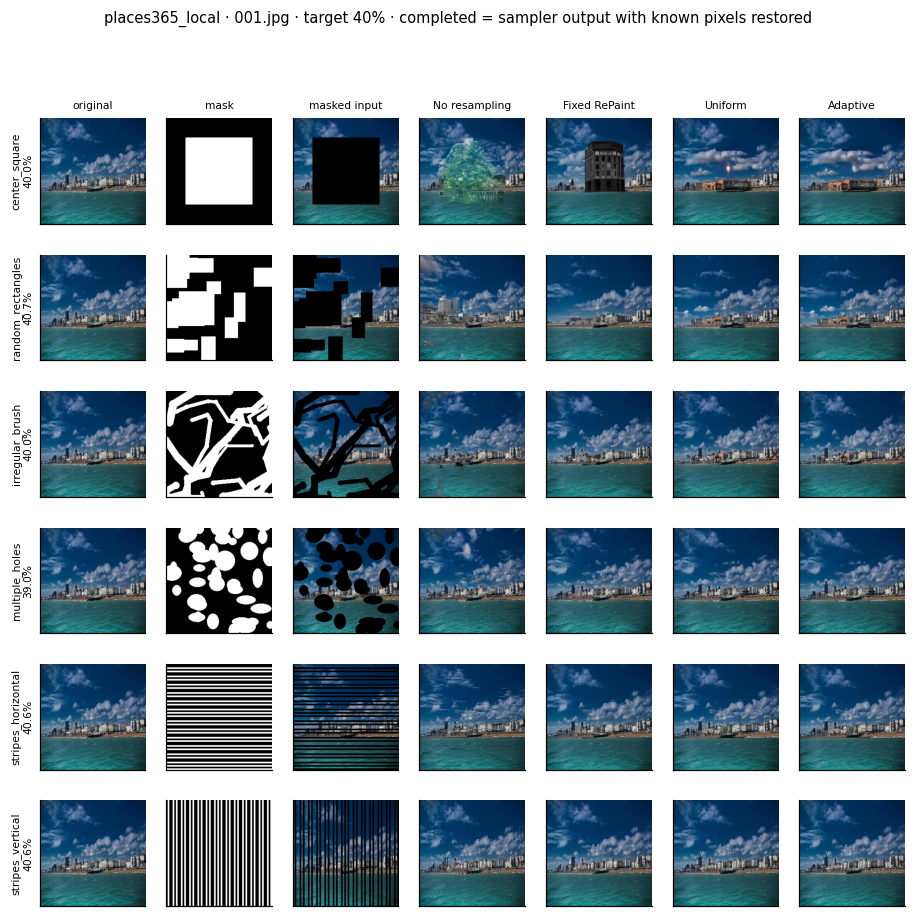

In [42]:
def gallery(dataset, ratio=None, image_id=None, families=None):
    sub = DF[DF.dataset == dataset]
    ratio = ratio if ratio is not None else sorted(sub.mask_target_ratio.unique())[len(sub.mask_target_ratio.unique()) // 2]
    image_id = image_id or sorted(sub.image_id.unique())[0]
    sub = sub[(sub.mask_target_ratio == ratio) & (sub.image_id == image_id)]
    fams = [f for f in (families or MASKS["families"]) if f in set(sub.mask_family)]
    if not fams:
        print("nothing to show"); return
    cols = ["original", "mask", "masked input"] + [LABEL[m] for m in METHODS]
    fig, axes = plt.subplots(len(fams), len(cols), figsize=(1.45 * len(cols), 1.5 * len(fams) + 0.4), squeeze=False)
    for r, fam in enumerate(fams):
        run_dir = Path(sub[sub.mask_family == fam].run_dir.iloc[0])
        files = ["original.png", "mask_missing_white.png", "masked_input.png"] + [f"{m}_composite.png" for m in METHODS]
        actual = sub[sub.mask_family == fam].mask_actual_ratio.iloc[0]
        for c, f in enumerate(files):
            ax = axes[r, c]; ax.imshow(Image.open(run_dir / "images" / f), cmap="gray" if "mask" in f else None)
            ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
            if r == 0: ax.set_title(cols[c], fontsize=7)
        axes[r, 0].set_ylabel(f"{fam}\n{actual:.1%}", fontsize=7)
    fig.suptitle(f"{dataset} · {image_id} · target {ratio:.0%} · completed = sampler output with known pixels restored")
    fig.savefig(FIG / f"gallery_{dataset}_{ratio:.2f}.png"); plt.show()

for d in DATASETS:
    gallery(d)

### 7.2 Metric tables, kept separate per dataset

In [43]:
TABLE_METRICS = [m for m in ["lpips_full", "lpips_missing_masked", "composite_full_psnr_db", "composite_full_ssim",
                               "composite_full_mse", "missing_mae", "missing_mse", "missing_psnr_db",
                               "boundary_inner_psnr_db", "raw_known_mae", "total_nfe", "total_wall_time_s"]
                 if m in DF and DF[m].notna().any()]
for d in DATASETS:
    t = DF[DF.dataset == d].groupby(["mask_family", "mask_target_ratio", "method"])[TABLE_METRICS].mean()
    t.insert(0, "n_images", DF[DF.dataset == d].groupby(["mask_family", "mask_target_ratio", "method"]).size())
    t.to_csv(ROOT / f"table_{d}.csv")
    print(f"=== {d} (means over images; saved table_{d}.csv)")
    display(t.round(4))

=== places365_local (means over images; saved table_places365_local.csv)


n_images  lpips_full  \
mask_family        mask_target_ratio method                                
center_square      0.25              adaptive              5      0.1899   
                                     fixed                 5      0.2028   
                                     no_resampling         5      0.2079   
                                     uniform               5      0.1883   
                   0.40              adaptive              5      0.2948   
                                     fixed                 5      0.3096   
                                     no_resampling         5      0.3413   
                                     uniform               5      0.2984   
irregular_brush    0.25              adaptive              5      0.0799   
                                     fixed                 5      0.0819   
                                     no_resampling         5      0.1316   
                                     uniform               5      0.0815   
                   0.40              adaptive              5      0.1291   
                                     fixed                 5      0.1299   
                                     no_resampling         5      0.1837   
                                     uniform               5      0.1293   
large_rectangle    0.25              adaptive              5      0.1596   
                                     fixed                 5      0.1647   
                                     no_resampling         5      0.1802   
                                     uniform               5      0.1592   
multiple_holes     0.25              adaptive              5      0.0846   
                                     fixed                 5      0.0779   
                                     no_resampling         5      0.1164   
                                     uniform               5      0.0808   
                   0.40              adaptive              5      0.1577   
                                     fixed                 5      0.1531   
                                     no_resampling         5      0.2244   
                                     uniform               5      0.1584   
random_rectangles  0.25              adaptive              5      0.1221   
                                     fixed                 5      0.1130   
                                     no_resampling         5      0.1406   
                                     uniform               5      0.1280   
                   0.40              adaptive              5      0.2072   
                                     fixed                 5      0.2102   
                                     no_resampling         5      0.2621   
                                     uniform               5      0.2052   
stripes_horizontal 0.25              adaptive              5      0.0468   
                                     fixed                 5      0.0449   
                                     no_resampling         5      0.0815   
                                     uniform               5      0.0463   
                   0.40              adaptive              5      0.0812   
                                     fixed                 5      0.0803   
                                     no_resampling         5      0.1670   
                                     uniform               5      0.0803   
stripes_vertical   0.25              adaptive              5      0.0537   
                                     fixed                 5      0.0553   
                                     no_resampling         5      0.0860   
                                     uniform               5      0.0528   
                   0.40              adaptive              5      0.0781   
                                     fixed                 5      0.0817   
                                     no_resampling         5      0.1616   
                        

### 7.3 LPIPS (or the primary metric) vs achieved mask coverage

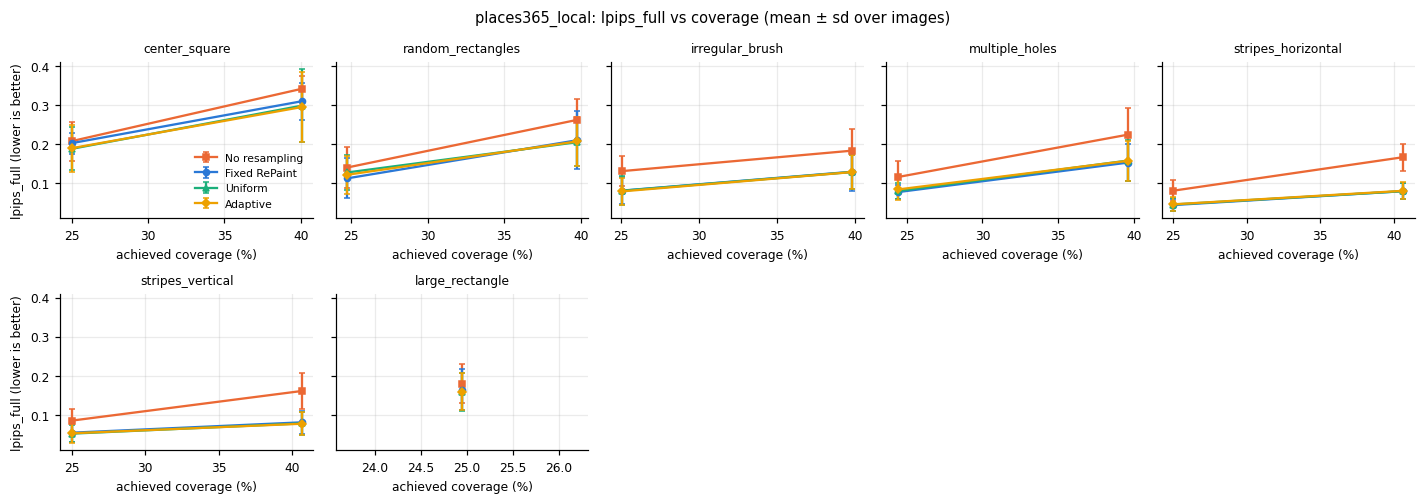

In [44]:
for d in DATASETS:
    sub = DF[DF.dataset == d]
    fams = [f for f in MASKS["families"] if f in set(sub.mask_family)]
    ncol = min(5, len(fams)); nrow = int(np.ceil(len(fams) / ncol))
    fig, axes = plt.subplots(nrow, ncol, figsize=(2.6 * ncol, 2.3 * nrow), squeeze=False, sharey=True)
    for i, fam in enumerate(fams):
        ax = axes[i // ncol, i % ncol]
        g = sub[sub.mask_family == fam].groupby(["method", "mask_target_ratio"]).agg(
            x=("mask_actual_ratio", "mean"), y=(PRIMARY, "mean"), s=(PRIMARY, "std")).reset_index()
        for m in METHODS:
            gm = g[g.method == m].sort_values("x")
            ax.errorbar(gm.x * 100, gm.y, yerr=gm.s.fillna(0), color=COLOR[m], marker=MARK[m], ms=4, lw=1.5,
                        capsize=2, label=LABEL[m])
        ax.set_title(fam, fontsize=8); ax.set_xlabel("achieved coverage (%)")
        if i % ncol == 0: ax.set_ylabel(f"{PRIMARY} ({'lower' if 'lpips' in PRIMARY or 'mae' in PRIMARY else 'higher'} is better)")
    for j in range(len(fams), nrow * ncol): axes[j // ncol, j % ncol].set_visible(False)
    axes[0, 0].legend(fontsize=7, frameon=False)
    fig.suptitle(f"{d}: {PRIMARY} vs coverage (mean ± sd over images)" + ("" if LPIPS_OK else " — LPIPS NOT VALID"))
    plt.tight_layout(); fig.savefig(FIG / f"coverage_{d}_{PRIMARY}.png"); plt.show()

### 7.4 Mask type × sampler (means over images and coverage levels)

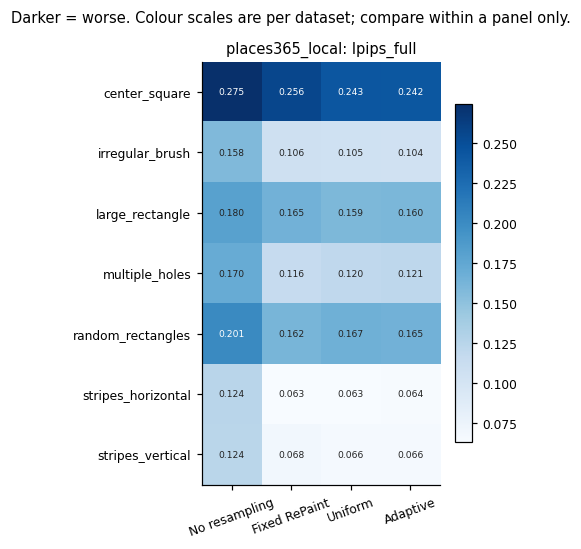

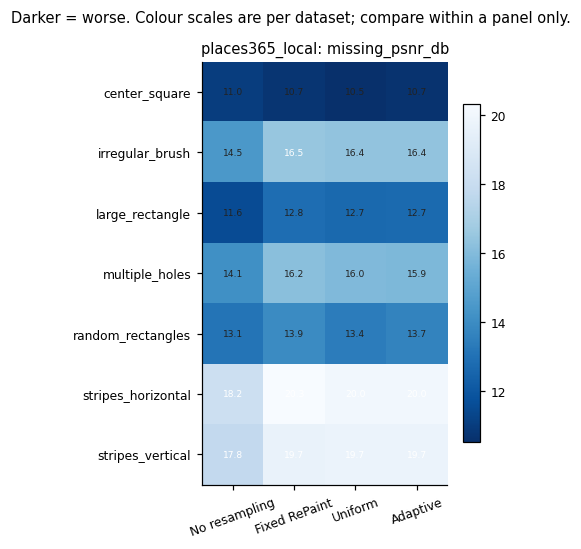

In [45]:
for metric in [m for m in (PRIMARY, "missing_psnr_db") if m in DF]:
    fig, axes = plt.subplots(1, len(DATASETS), figsize=(4.2 * len(DATASETS), 0.38 * len(MASKS["families"]) + 1.6), squeeze=False)
    for ax, d in zip(axes[0], DATASETS):
        p = DF[DF.dataset == d].pivot_table(index="mask_family", columns="method", values=metric, aggfunc="mean")
        p = p[[m for m in METHODS if m in p]]
        im = ax.imshow(p.values, cmap="Blues" if metric in ("lpips_full", "missing_mae", "lpips_missing_masked") else "Blues_r", aspect="auto")
        ax.set_xticks(range(p.shape[1]), [LABEL[m] for m in p.columns], rotation=20); ax.set_yticks(range(p.shape[0]), p.index)
        for (r, c), v in np.ndenumerate(p.values):
            ax.text(c, r, f"{v:.3f}" if abs(v) < 10 else f"{v:.1f}", ha="center", va="center", fontsize=6,
                    color="white" if im.norm(v) > 0.6 else "#222")
        ax.set_title(f"{d}: {metric}"); ax.grid(False)
        fig.colorbar(im, ax=ax, shrink=0.8)
    fig.suptitle("Darker = worse. Colour scales are per dataset; compare within a panel only."
                 + ("" if LPIPS_OK or "lpips" not in metric else "  LPIPS NOT VALID"))
    plt.tight_layout(); fig.savefig(FIG / f"heatmap_{metric}.png"); plt.show()

### 7.5 Paired adaptive − uniform (same image, mask, seeds and NFE)

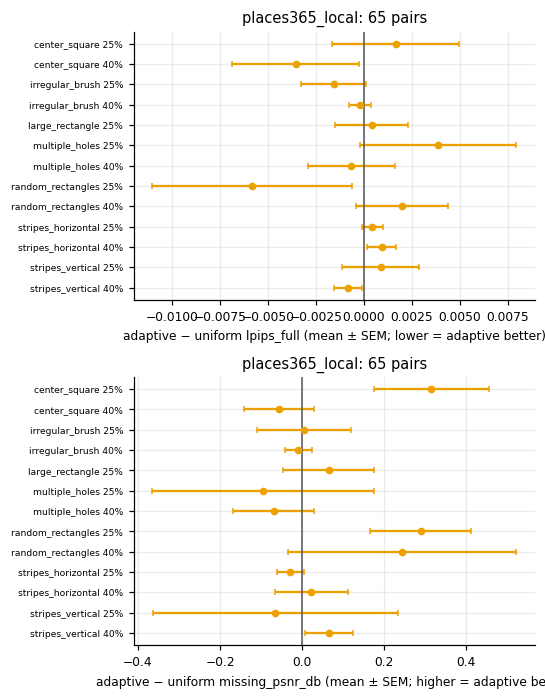

,dataset,mask_family,mask_target_ratio,metric,comparison,n_pairs,mean_diff,std_diff,sem_diff,n_adaptive_better,n_uniform_better,n_ties,lower_is_better
0,places365_local,center_square,0.25,lpips_full,adaptive - uniform,5,0.0016,0.0074,0.0033,2,3,0,True
1,places365_local,center_square,0.25,missing_psnr_db,adaptive - uniform,5,0.3149,0.3121,0.1396,4,1,0,False
2,places365_local,center_square,0.40,lpips_full,adaptive - uniform,5,-0.0035,0.0074,0.0033,3,1,1,True
3,places365_local,center_square,0.40,missing_psnr_db,adaptive - uniform,5,-0.0562,0.1909,0.0854,1,3,1,False
4,places365_local,irregular_brush,0.25,lpips_full,adaptive - uniform,5,-0.0016,0.0038,0.0017,3,2,0,True
5,places365_local,irregular_brush,0.25,missing_psnr_db,adaptive - uniform,5,0.0044,0.2578,0.1153,2,3,0,False
6,places365_local,irregular_brush,0.40,lpips_full,adaptive - uniform,5,-0.0002,0.0013,0.0006,1,2,2,True
7,places365_local,irregular_brush,0.40,missing_psnr_db,adaptive - uniform,5,-0.0088,0.0731,0.0327,1,2,2,False
8,places365_local,large_rectangle,0.25,lpips_full,adaptive - uniform,5,0.0004,0.0043,0.0019,1,2,2,True
9,places365_local,large_rectangle,0.25,missing_psnr_db,adaptive - uniform,5,0.0656,0.2479,0.1109,2,1,2,False


In [46]:
from src.faces_places2_study import paired_differences
pair_metrics = [m for m in (PRIMARY, "missing_psnr_db") if m in DF]
PAIRED = paired_differences(DF, "adaptive", "uniform", pair_metrics)
PAIRED.to_csv(ROOT / "paired_adaptive_vs_uniform.csv", index=False)
fig, axes = plt.subplots(len(pair_metrics), len(DATASETS), figsize=(5 * len(DATASETS), 3.2 * len(pair_metrics)), squeeze=False)
for r, metric in enumerate(pair_metrics):
    for c, d in enumerate(DATASETS):
        ax = axes[r, c]
        p = PAIRED[(PAIRED.dataset == d) & (PAIRED.metric == metric)].reset_index(drop=True)
        labels = [f"{f} {q:.0%}" for f, q in zip(p.mask_family, p.mask_target_ratio)]
        ax.errorbar(p.mean_diff, range(len(p)), xerr=p.sem_diff.fillna(0), fmt="o", color=COLOR["adaptive"], ms=4, capsize=2)
        ax.axvline(0, color="#555", lw=1)
        ax.set_yticks(range(len(p)), labels, fontsize=6); ax.invert_yaxis()
        better = "lower" if metric in ("lpips_full", "lpips_missing_masked", "missing_mae") else "higher"
        ax.set_xlabel(f"adaptive − uniform {metric} (mean ± SEM; {better} = adaptive better)")
        ax.set_title(f"{d}: {int(p.n_pairs.sum()) if len(p) else 0} pairs"
                     + ("" if LPIPS_OK or "lpips" not in metric else " (LPIPS NOT VALID)"))
plt.tight_layout(); fig.savefig(FIG / "paired_adaptive_vs_uniform.png"); plt.show()
display(PAIRED.round(4))

### 7.6 Cross-dataset comparison (within-dataset quantities only)

dataset,places365_local
mask_family,
center_square,1
large_rectangle,2
random_rectangles,3
multiple_holes,4
irregular_brush,5
stripes_vertical,6
stripes_horizontal,7


method,fixed,uniform,adaptive
% change in lpips_full vs no resampling,,,
places365_local,-28.12,-28.67,-29.01


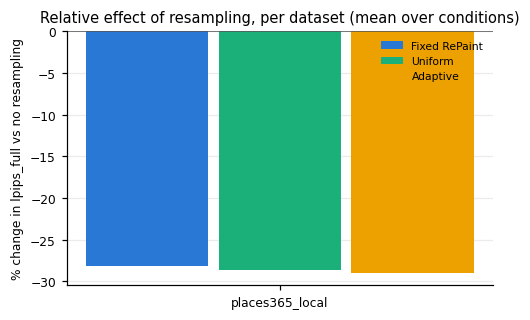

In [47]:
from src.faces_places2_study import mask_difficulty_ranking, relative_to_no_resampling
RANK = mask_difficulty_ranking(DF, "fixed", PRIMARY) if "fixed" in METHODS else pd.DataFrame()
if len(RANK):
    wide = RANK.pivot(index="mask_family", columns="dataset", values="rank_most_challenging")
    display(wide.sort_values(DATASETS[0]))
    if len(DATASETS) == 2:
        fig, ax = plt.subplots(figsize=(4.2, 0.32 * len(wide) + 1.5))
        for fam, row in wide.iterrows():
            ax.plot([0, 1], [row[DATASETS[0]], row[DATASETS[1]]], color="#2a78d6", marker="o", lw=1.2)
            ax.text(-0.04, row[DATASETS[0]], fam, ha="right", va="center", fontsize=7)
            ax.text(1.04, row[DATASETS[1]], fam, ha="left", va="center", fontsize=7)
        ax.set_xticks([0, 1], DATASETS); ax.set_yticks(range(1, len(wide) + 1)); ax.invert_yaxis()
        ax.set_xlim(-0.8, 1.8); ax.set_ylabel("rank (1 = most challenging)")
        ax.set_title(f"Mask difficulty rank by {PRIMARY}, fixed RePaint" + ("" if LPIPS_OK else "\n(LPIPS NOT VALID)")); ax.grid(False)
        fig.savefig(FIG / "mask_difficulty_rank.png"); plt.show()
REL = relative_to_no_resampling(DF, PRIMARY) if "no_resampling" in METHODS else pd.DataFrame()
if len(REL):
    agg = REL.groupby(["dataset", "method"])["mean"].mean().unstack("method")
    agg = agg[[m for m in ["fixed", "uniform", "adaptive"] if m in agg]]
    display((agg * 100).round(2).rename_axis(f"% change in {PRIMARY} vs no resampling"))
    fig, ax = plt.subplots(figsize=(5, 3)); w = 0.8 / agg.shape[1]
    for i, m in enumerate(agg.columns):
        ax.bar(np.arange(len(agg)) + (i - (agg.shape[1] - 1) / 2) * w, agg[m] * 100, w * 0.92, color=COLOR[m], label=LABEL[m])
    ax.axhline(0, color="#555", lw=1); ax.set_xticks(range(len(agg)), agg.index)
    ax.set_ylabel(f"% change in {PRIMARY} vs no resampling"); ax.legend(frameon=False, fontsize=7); ax.grid(axis="x", visible=False)
    ax.set_title("Relative effect of resampling, per dataset (mean over conditions)" + ("" if LPIPS_OK else "\nLPIPS NOT VALID"))
    fig.savefig(FIG / "relative_to_no_resampling.png"); plt.show()

### 7.7 Compute: NFE and wall-clock time (separate panels)

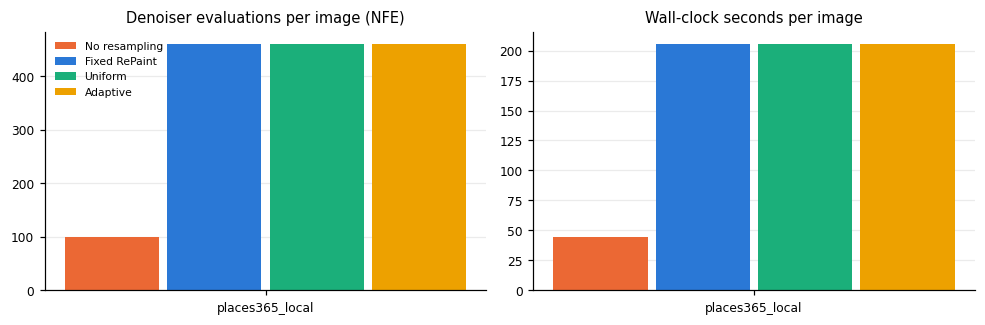

Verified: uniform and adaptive total NFE are identical for every paired run.


In [48]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
agg = DF.groupby(["dataset", "method"])[["total_nfe", "total_wall_time_s"]].mean().reset_index()
for ax, col, title in zip(axes, ["total_nfe", "total_wall_time_s"], ["Denoiser evaluations per image (NFE)", "Wall-clock seconds per image"]):
    w = 0.8 / len(METHODS)
    for i, m in enumerate(METHODS):
        v = agg[agg.method == m].set_index("dataset").reindex(DATASETS)[col]
        ax.bar(np.arange(len(DATASETS)) + (i - (len(METHODS) - 1) / 2) * w, v, w * 0.92, color=COLOR[m], label=LABEL[m])
    ax.set_xticks(range(len(DATASETS)), DATASETS); ax.set_title(title); ax.grid(axis="x", visible=False)
axes[0].legend(frameon=False, fontsize=7)
plt.tight_layout(); fig.savefig(FIG / "compute.png"); plt.show()
check = DF.pivot_table(index=["dataset", "mask_family", "mask_target_ratio", "image_id"], columns="method", values="total_nfe")
if {"uniform", "adaptive"} <= set(check.columns):
    assert (check["uniform"] == check["adaptive"]).all(), "uniform/adaptive NFE mismatch"
    print("Verified: uniform and adaptive total NFE are identical for every paired run.")

### 7.8 What the executed results support

The cell below states only what the saved numbers show and prints the evidence it is based on. With few images it reports descriptive counts, not significance. For smoke runs it refuses to draw conclusions.

In [49]:
if KIND == "smoke_fake":
    print("Smoke A (fake denoiser): no conclusions about datasets, masks or samplers can be drawn.")
else:
    n_img = DF.groupby("dataset").image_id.nunique().to_dict()
    print(f"Run kind: {KIND}; images per dataset: {n_img}; primary metric: {PRIMARY} (LPIPS valid: {LPIPS_OK})")
    if len(RANK):
        for d in DATASETS:
            top = RANK[RANK.dataset == d].nsmallest(3, "rank_most_challenging")
            print(f"[{d}] most challenging mask families for fixed RePaint by mean {PRIMARY}: "
                  + ", ".join(f"{r.mask_family} ({r['mean']:.4f}, n={int(r['count'])})" for _, r in top.iterrows()))
    p = PAIRED[PAIRED.metric == PRIMARY]
    if len(p):
        better_col = [c for c in p.columns if c.startswith("n_adaptive_better")][0]
        worse_col = [c for c in p.columns if c.startswith("n_uniform_better")][0]
        for d in DATASETS:
            q = p[p.dataset == d]
            lower = q.lower_is_better.iloc[0]
            favour = (q.mean_diff < 0).sum() if lower else (q.mean_diff > 0).sum()
            print(f"[{d}] adaptive vs uniform on {PRIMARY}: conditions favouring adaptive {favour}/{len(q)}; "
                  f"image pairs adaptive better {int(q[better_col].sum())}, uniform better {int(q[worse_col].sum())}, "
                  f"ties {int(q.n_ties.sum())}")
        per_ds = {d: (p[p.dataset == d].mean_diff < 0).mean() if p.lower_is_better.iloc[0] else (p[p.dataset == d].mean_diff > 0).mean()
                  for d in DATASETS}
        consistent = all(v > 0.5 for v in per_ds.values()) or all(v < 0.5 for v in per_ds.values())
        print("Direction of the adaptive − uniform effect is", "the same" if consistent else "NOT the same",
              "in both datasets (share of conditions favouring adaptive:", {k: round(v, 2) for k, v in per_ds.items()}, ").")
    print("These are descriptive statements about the executed runs only. Report spreads and image counts; "
          "small samples cannot establish a consistent improvement.")

Run kind: full; images per dataset: {'places365_local': 5}; primary metric: lpips_full (LPIPS valid: True)
[places365_local] most challenging mask families for fixed RePaint by mean lpips_full: center_square (0.2562, n=10), large_rectangle (0.1647, n=5), random_rectangles (0.1616, n=10)
[places365_local] adaptive vs uniform on lpips_full: conditions favouring adaptive 6/13; image pairs adaptive better 29, uniform better 28, ties 8
Direction of the adaptive − uniform effect is the same in both datasets (share of conditions favouring adaptive: {'places365_local': np.float64(0.46)} ).
These are descriptive statements about the executed runs only. Report spreads and image counts; small samples cannot establish a consistent improvement.
